# Quickstart on the free-tier samples

The files in `data/samples/` are **6-second excerpts (49,153 points at 8192 Hz) of real tseriz output**, cropped from t = 7 s to 13 s of the 20 s series. The degradation starts at **3.0 s** in these files (10 s in the original). They fit inside the 50,000-point limit of the Free plan.

| Folder | Files | Seed |
|---|---|---|
| `seed4242/` | `baseline`, `case_a` (naive noise), `case_b` (inner-race fault) | 4242 |
| `seed1001/` | `case_a`, `case_b`, `case_c` (weaker constant-amplitude fault) | 1001 |

Within a folder the healthy part is bit-identical across files, so subtracting the baseline isolates the effect of the degradation.

**What this notebook can and cannot show.** The excerpts contain only the first 30 % of the 10 s degradation ramp (impact amplitude 0.1 g to about 0.22 g in Case B, white noise x1 to x3.4 in Case A) and 3 s of healthy data to calibrate thresholds on. The numbers therefore differ from the ones in the article, which come from the full 20 s series and 30 seeds per case (`notebooks/bearing_degradation.ipynb`). Use the samples to see the signatures, not to benchmark detectors.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
%matplotlib inline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "tools"))
from bearing_lib import FS, BPFI, band_env, fit_lines, envelope_spectrum, window_features, alarm_time

SAMPLES = ROOT / "data" / "samples"
ONSET = 3.0   # seconds into the sample file
COLORS = {"baseline": "#6b7280", "case_a": "#d97706", "case_b": "#2563eb", "case_c": "#2a9d8f"}
LABELS = {"baseline": "Baseline", "case_a": "Case A (naive noise)", "case_b": "Case B (inner-race fault)", "case_c": "Case C (weak fault)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})

def load(folder, names):
    X = {k: pd.read_csv(SAMPLES / folder / f"{k}.csv")["vibration"].to_numpy(float) for k in names}
    n = len(next(iter(X.values())))
    return np.arange(n) / FS, X   # sample index as time axis (the CSV timestamps drift by a few ppm)

t, X = load("seed4242", ["baseline", "case_a", "case_b"])
print({k: len(v) for k, v in X.items()}, "points; duration", round(t[-1], 3), "s")

{'baseline': 49153, 'case_a': 49153, 'case_b': 49153} points; duration 6.0 s


## 1. The raw data, and what changes at the onset
Same seed, so `series - baseline` is exactly what the degradation added. Case A adds noise only; Case B adds a train of decaying impacts at 162 Hz.

shaft-line amplitudes before the onset [g] (config: 0.5 / 0.2 / 0.1):
  Baseline                     0.501 / 0.201 / 0.100
  Case A (naive noise)         0.501 / 0.201 / 0.100
  Case B (inner-race fault)    0.501 / 0.201 / 0.100
healthy part identical across files: True


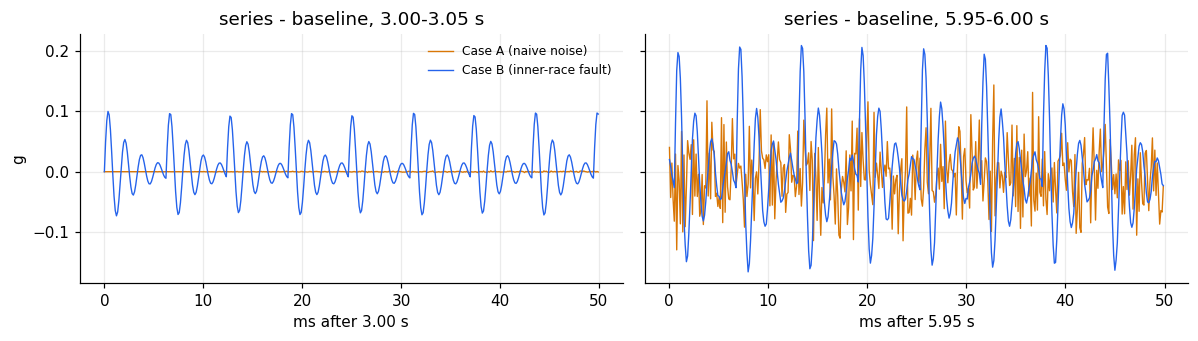

In [2]:
pre = t < ONSET
print("shaft-line amplitudes before the onset [g] (config: 0.5 / 0.2 / 0.1):")
for k, x in X.items():
    print(f"  {LABELS[k]:28s}", " / ".join(f"{a:.3f}" for a in fit_lines(x[pre], t[pre])[1]))
print("healthy part identical across files:", all(np.array_equal(X[k][pre], X["baseline"][pre]) for k in X))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, (lo, hi) in zip(ax, [(ONSET, ONSET + 0.05), (t[-1] - 0.05, t[-1])]):
    m = (t >= lo) & (t < hi)
    for k in ("case_a", "case_b"):
        a.plot((t[m] - lo) * 1e3, (X[k] - X["baseline"])[m], color=COLORS[k], lw=.9, label=LABELS[k])
    a.set_xlabel(f"ms after {lo:.2f} s"); a.set_title(f"series - baseline, {lo:.2f}-{hi:.2f} s")
ax[0].set_ylabel("g"); ax[0].legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

## 2. Spectra: healthy part vs degraded part
Case A lifts the whole noise floor. Case B adds a comb at multiples of 162 Hz on a 600 Hz resonance hump, much smaller in energy.

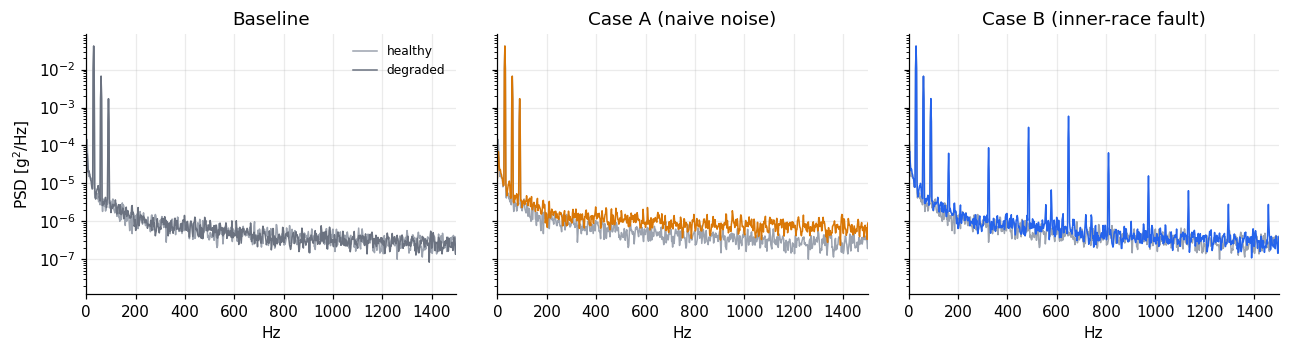

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, k in zip(ax, X):
    for (lo, hi), ls in (((0, ONSET), "healthy"), ((ONSET, t[-1] + 1 / FS), "degraded")):
        m = (t >= lo) & (t < hi); f, P = welch(X[k][m], FS, nperseg=4096)
        a.semilogy(f, P, color=COLORS[k] if ls == "degraded" else "#9ca3af", lw=1, label=ls)
    a.set_xlim(0, 1500); a.set_title(LABELS[k]); a.set_xlabel("Hz")
ax[0].set_ylabel("PSD [g$^2$/Hz]"); ax[0].legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

## 3. Envelope spectrum of the 400-800 Hz band
The repetition rate of the impacts shows up as a line at 162 Hz (and harmonics) only in Case B. Case A raises the envelope noise but has no line.

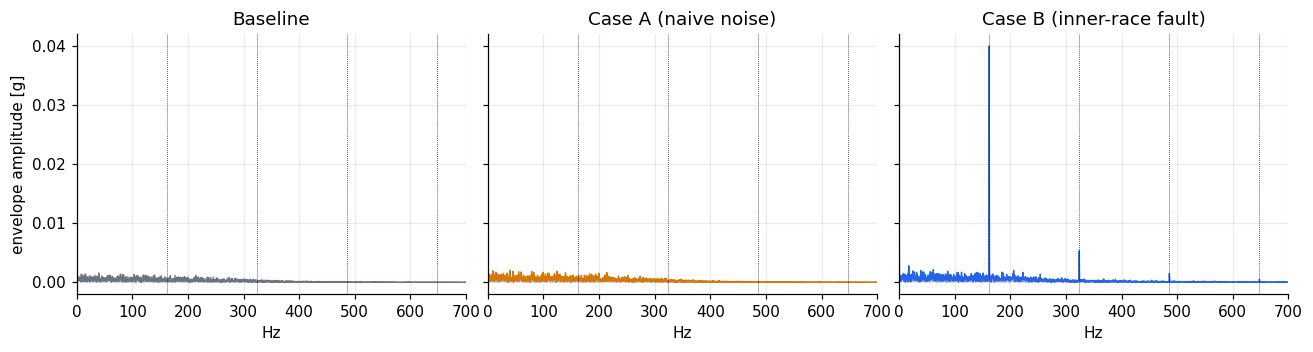

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, k in zip(ax, X):
    for (lo, hi), c in (((0, ONSET), "#9ca3af"), ((ONSET, t[-1] + 1 / FS), COLORS[k])):
        m = (t >= lo) & (t < hi); f, E = envelope_spectrum(X[k][m]); a.plot(f, E, color=c, lw=.9)
    a.set_xlim(0, 700); a.set_title(LABELS[k]); a.set_xlabel("Hz")
    for h in (1, 2, 3, 4): a.axvline(h * BPFI, color="k", lw=.5, ls=":")
ax[0].set_ylabel("envelope amplitude [g]"); fig.tight_layout(); plt.show()

## 4. Indicators and alarm delay
1 s windows, 0.25 s step. Threshold = mean + 4 sd of the indicator over the healthy windows (here only the windows that end before 3.0 s, so nine heavily overlapping windows). Alarm after 3 consecutive exceedances; the delay is measured from the onset to the end of the third window. With so little healthy data the thresholds are noisy, so treat the table as an illustration of the method.

In [5]:
FEATS = {"rms": "Overall RMS", "band_rms": "RMS 400-800 Hz", "bpfi_line": "Envelope line at 162 Hz"}

def delays(X):
    rows = {}
    for k, x in X.items():
        F = window_features(x, t); h = F[F.t_end <= ONSET]
        rows[LABELS[k]] = {FEATS[f]: alarm_time(F.t_end, F[f], h[f].mean() + 4 * h[f].std()) - ONSET for f in FEATS}
    return pd.DataFrame(rows).T

delays(X).round(2)   # NaN = no alarm before the end of the excerpt

,Overall RMS,RMS 400-800 Hz,Envelope line at 162 Hz
Baseline,NaN,NaN,NaN
Case A (naive noise),3.0,1.75,NaN
Case B (inner-race fault),3.0,0.75,1.0


## 5. Case C: the weaker, constant-amplitude fault (seed 1001)
Same inner-race fault as Case B but with constant 0.1 g impacts. The envelope line still appears while overall RMS barely moves; compare with Case A (noise only).

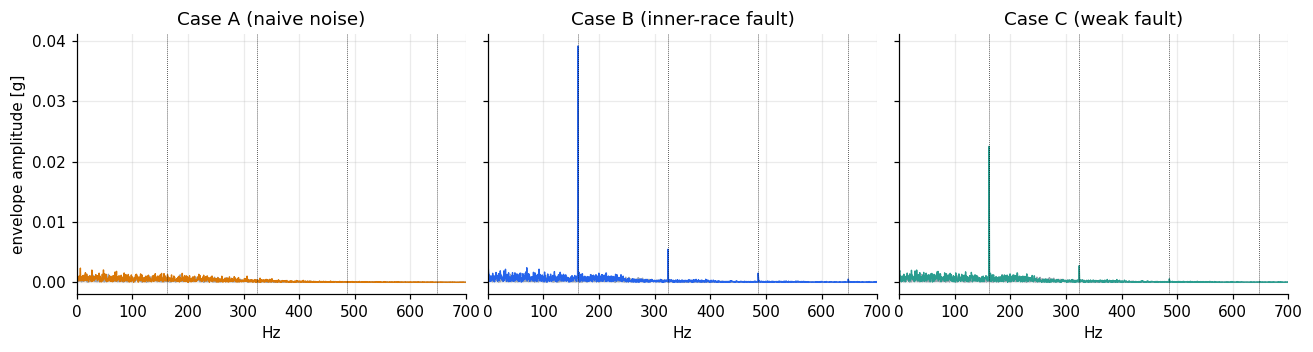

,Overall RMS,RMS 400-800 Hz,Envelope line at 162 Hz
Case A (naive noise),NaN,1.25,NaN
Case B (inner-race fault),NaN,0.75,1.0
Case C (weak fault),NaN,0.75,1.0


In [6]:
t, Y = load("seed1001", ["case_a", "case_b", "case_c"])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, k in zip(ax, Y):
    for (lo, hi), c in (((0, ONSET), "#9ca3af"), ((ONSET, t[-1] + 1 / FS), COLORS[k])):
        m = (t >= lo) & (t < hi); f, E = envelope_spectrum(Y[k][m]); a.plot(f, E, color=c, lw=.9)
    a.set_xlim(0, 700); a.set_title(LABELS[k]); a.set_xlabel("Hz")
    for h in (1, 2, 3, 4): a.axvline(h * BPFI, color="k", lw=.5, ls=":")
ax[0].set_ylabel("envelope amplitude [g]"); fig.tight_layout(); plt.show()
delays(Y).round(2)

## Next steps
- Regenerate full-length series with `python tools/generate_batch.py --reference-set` and run `notebooks/bearing_degradation.ipynb` to reproduce the article.
- Change the configs in `configs/` (impact amplitude, ramp, noise levels) and import them in tseriz to build your own degradation scenarios.